# 05. 지속성 가설 검증 (H5, H6)

지금 점포당 매출이 높은 상권이 앞으로도 좋을지를 두 시점을 비교해서 봅니다.

| 가설 | 내용 | 판정 기준 |
|---|---|---|
| H5 | 2년 전 점포당 매출 순위가 높았던 상권은 지금도 순위가 높다 | 2024Q2와 2026Q2의 스피어만 ρ ≥ 0.5 |
| H6 | 폐업률이 높은 상권은 다음 해 점포당 매출 성장률이 낮다 | 2025Q2 폐업률과 2025Q2→2026Q2 성장률의 r < 0, p < 0.05 |

04 노트북처럼 세 가지 버전으로 돌립니다. 두 시점을 비교하니까 기본 버전은 두 분기 모두 결제부족이 아닌 상권만 씁니다.

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

load_dotenv('../.env')
url = URL.create(
    drivername='postgresql+psycopg2',
    username=os.environ['PGUSER'],
    password=os.environ['PGPASSWORD'],
    host=os.environ['PGHOST'],
    port=int(os.environ['PGPORT']),
    database=os.environ['PGDATABASE'],
)
engine = create_engine(url)

# 분석_대상 뷰는 04 노트북에서 만들었음. 여기서는 읽기만 함
rows = pd.read_sql('SELECT * FROM 분석_대상', engine)
print(rows.shape)

(23568, 27)


#### 코드 읽기
- 04 노트북과 같은 준비 과정입니다. 이번에는 회귀를 안 해서 statsmodels는 불러오지 않았습니다.
- `분석_대상` 뷰는 04 노트북에서 SQL 파일을 실행할 때 만들어졌습니다. 그래서 04를 먼저 돌려야 이 노트북이 돌아갑니다.
- `pd.read_sql('SELECT * FROM 분석_대상', engine)`: 이번에는 분기를 거르지 않고 22개 분기 전체를 가져옵니다.

## 0. 두 분기를 옆으로 붙이는 함수

같은 상권의 2년 전 값과 지금 값을 비교하려면 두 분기를 상권 코드로 옆에 붙여야 합니다. H5, H6, 다른 연도 비교에서 계속 쓰니까 함수로 만듭니다.

In [2]:
def make_pair(before_q, after_q):
    cols = ['상권_코드', '상권_코드_명', '점포당_매출', 'ln_점포당_매출', '폐업률', '결제부족']
    before = rows[rows['기준_년분기_코드'] == before_q][cols]
    after = rows[rows['기준_년분기_코드'] == after_q][cols]

    # 상권 코드가 양쪽에 다 있는 상권만 남음 (inner join)
    pair = before.merge(after, on='상권_코드', suffixes=('_전', '_후'))

    # 로그끼리 빼면 로그 성장률. 0.1이면 약 10% 성장
    pair['성장률_로그'] = pair['ln_점포당_매출_후'] - pair['ln_점포당_매출_전']
    return pair


def make_versions(pair):
    base = pair[(pair['결제부족_전'] == 0) & (pair['결제부족_후'] == 0)]
    no_city = base[base['상권_코드_명_전'] != '시청역_8번']
    return {
        '기본': base,
        '결제부족 포함': pair,
        '시청역_8번 제외': no_city,
    }

#### 코드 읽기
- `def make_pair(before_q, after_q):`: 앞 분기 코드와 뒤 분기 코드를 받아서 두 분기를 붙인 표를 돌려줍니다.
- `cols = [...]`: 필요한 컬럼만 고릅니다. 다 가져오면 붙였을 때 컬럼이 너무 많아집니다.
- `before.merge(after, on='상권_코드', ...)`: 상권 코드가 같은 줄끼리 옆으로 붙입니다. SQL의 `JOIN ... ON` 과 같고 기본이 inner join이라 양쪽에 다 있는 상권만 남습니다.
- `suffixes=('_전', '_후')`: 양쪽에 같은 이름의 컬럼(점포당_매출 등)이 있으니 앞쪽에는 `_전`, 뒤쪽에는 `_후`를 붙여 구분합니다.
- `pair['성장률_로그'] = ...`: ln(뒤) − ln(앞) = ln(뒤 ÷ 앞)입니다. 성장률이 크지 않을 때는 보통 성장률과 거의 같습니다. 매출이 아주 작았던 상권에서 +500% 같은 값이 튀는 것도 덜합니다.
- `def make_versions(pair):`: 붙인 표로 세 버전을 만듭니다.
- `(조건1) & (조건2)`: pandas에서 "그리고"는 `and`가 아니라 `&`를 쓰고, 조건마다 괄호로 감싸야 합니다.

## 1. H5. 2년 전 순위가 지금도 유지되는가

In [3]:
h5_pair = make_pair(20242, 20262)
h5_versions = make_versions(h5_pair)

result = []
for name, data in h5_versions.items():
    rho, p = stats.spearmanr(data['점포당_매출_전'], data['점포당_매출_후'])
    result.append({'버전': name, '상권_수': len(data), 'ρ': round(rho, 3), 'p값': p})

pd.DataFrame(result)

,버전,상권_수,ρ,p값
0,기본,964,0.907,0.0
1,결제부족 포함,1021,0.913,0.0
2,시청역_8번 제외,963,0.907,0.0


#### 코드 읽기
- `make_pair(20242, 20262)`: 2024년 2분기와 2026년 2분기를 붙입니다.
- `stats.spearmanr(a, b)`: 스피어만 순위상관입니다. 값을 순위로 바꾼 뒤 피어슨 상관을 구하는 것과 같습니다. 순위만 보니까 로그를 취하든 안 취하든 결과가 같고 극단값 영향도 거의 없습니다.
- 나머지는 04 노트북의 for문 구조와 같습니다.

기본 버전 ρ는 0.907로 기준(0.5)을 크게 넘습니다. H5는 지지됩니다. 2년 전에 점포당 매출 순위가 높았던 상권은 지금도 거의 그대로 순위가 높습니다. 세 버전 모두 0.9가 넘습니다.

p값이 0.0으로 나온 건 값이 너무 작아서 컴퓨터가 표현할 수 있는 가장 작은 수보다 작기 때문입니다. 정말 0이라는 뜻은 아닙니다.

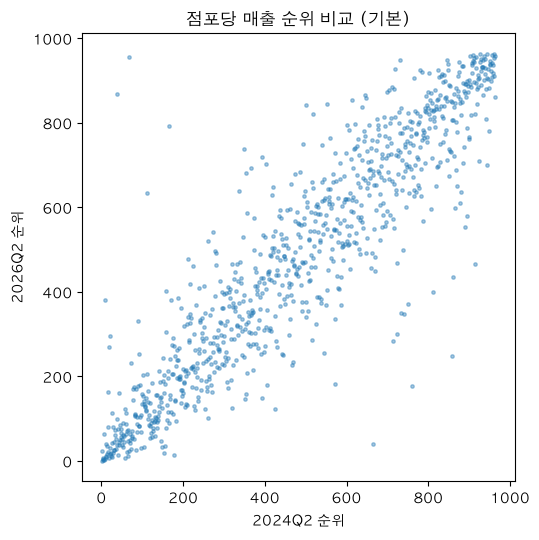

In [4]:
base5 = h5_versions['기본'].copy()

# 순위: 매출이 큰 상권이 1등
base5['순위_전'] = base5['점포당_매출_전'].rank(ascending=False)
base5['순위_후'] = base5['점포당_매출_후'].rank(ascending=False)

plt.figure(figsize=(5.5, 5.5))
plt.scatter(base5['순위_전'], base5['순위_후'], s=6, alpha=0.4)
plt.xlabel('2024Q2 순위')
plt.ylabel('2026Q2 순위')
plt.title('점포당 매출 순위 비교 (기본)')
plt.tight_layout()
plt.show()

#### 코드 읽기
- `h5_versions['기본'].copy()`: 기본 버전을 꺼내 복사합니다. 컬럼을 추가할 거라 `.copy()`를 붙였습니다.
- `.rank(ascending=False)`: 값에 순위를 매깁니다. `ascending=False`라서 큰 값이 1등입니다.
- 산점도에서 점들이 왼쪽 아래에서 오른쪽 위로 이어지는 대각선에 모일수록 순위가 유지된 겁니다.

In [5]:
# 2024Q2 상위 10% 상권이 2026Q2에도 상위 10%에 있는지
n = len(base5)
top_n = round(n * 0.1)

base5['상위10_전'] = base5['순위_전'] <= top_n
base5['상위10_후'] = base5['순위_후'] <= top_n

print('상권 수:', n, '/ 상위 10% =', top_n, '곳')
pd.crosstab(base5['상위10_전'], base5['상위10_후'])

상권 수: 964 / 상위 10% = 96 곳


상위10_후,False,True
상위10_전,,
False,843,25
True,25,71


#### 코드 읽기
- `top_n = round(n * 0.1)`: 상위 10%가 몇 곳인지 계산합니다.
- `base5['순위_전'] <= top_n`: 순위가 top_n 안이면 True입니다.
- `pd.crosstab(...)`: 2년 전 상위 10% 여부와 지금 상위 10% 여부를 교차표로 셉니다. 오른쪽 아래(True, True) 칸이 상위권을 지킨 상권 수입니다.
- 5단계에서 후보를 고를 때 "지금 1등"만 믿어도 되는지 판단하는 데 씁니다.

2024년 2분기 상위 10%(96곳) 가운데 71곳(74%)이 2026년 2분기에도 상위 10%에 있습니다. 지금 숫자로 후보를 골라도 된다는 근거가 됩니다. 반대로 상위권 네 곳 중 한 곳은 2년 사이에 밀려났으니 5단계에서는 순위와 함께 최근 추세도 확인합니다.

## 2. H6. 폐업률과 다음 해 성장률

먼저 폐업률 값부터 확인합니다.

In [6]:
h6_pair = make_pair(20252, 20262)
h6_versions = make_versions(h6_pair)

print(h6_versions['기본']['폐업률_전'].describe().round(1))
print()
print('폐업률 0인 상권 비율:', round((h6_versions['기본']['폐업률_전'] == 0).mean(), 3))

# 22개 분기 전체에서 100%가 넘는 이상한 값이 있는지
print('폐업률 100 초과 (전체 분기):', (rows['폐업률'] > 100).sum(), '줄')

count    982.0
mean       4.6
std        7.6
min        0.0
25%        0.0
50%        0.0
75%        7.0
max       60.0
Name: 폐업률_전, dtype: float64

폐업률 0인 상권 비율: 0.571
폐업률 100 초과 (전체 분기): 1 줄


#### 코드 읽기
- `make_pair(20252, 20262)`: 2025년 2분기와 2026년 2분기를 붙입니다. `폐업률_전`이 2025년 2분기 폐업률입니다.
- `.describe()`: 폐업률 분포를 요약합니다.
- `(... == 0).mean()`: True/False의 평균은 True의 비율입니다. 폐업률이 0인 상권의 비율이 됩니다.
- `(rows['폐업률'] > 100).sum()`: 비율은 100%를 넘을 수 없는데 넘는 값이 있는지 전체 분기에서 셉니다.

2025년 2분기 폐업률은 중앙값이 0%이고 상권의 57%가 0입니다. 점포가 적은 상권은 한 곳만 문을 닫아도 폐업률이 크게 뜁니다. 점포가 5개면 한 곳만 닫아도 20%입니다. 그래서 이 지표는 상권마다, 분기마다 들쭉날쭉합니다.

100%를 넘는 값도 전체 분기에서 1줄 있습니다(방배아이파크아파트 2021년 3분기, 120%). 비율이 100%를 넘을 수는 없으니 분모 기준이 다르거나 기록 오류로 보입니다. H6 판정에 쓰는 2025년 2분기에는 없어서 결과에는 영향이 없습니다. 데이터 이슈 로그에 적어 둡니다.

In [7]:
result = []
for name, data in h6_versions.items():
    r, p = stats.pearsonr(data['폐업률_전'], data['성장률_로그'])
    result.append({'버전': name, '상권_수': len(data), 'r': round(r, 3), 'p값': p})

pd.DataFrame(result)

,버전,상권_수,r,p값
0,기본,982,-0.073,0.022153
1,결제부족 포함,1035,-0.050,0.108775
2,시청역_8번 제외,981,-0.073,0.022223


#### 코드 읽기
- 세 버전마다 2025년 2분기 폐업률과 그다음 1년 로그 성장률의 피어슨 상관을 구합니다.

기본 버전은 r = -0.073, p = 0.022로 기준(r < 0, p < 0.05)을 넘습니다. 그런데 결제부족을 포함하면 p = 0.109로 기준을 넘지 못합니다. r이 -0.07이면 폐업률이 성장률 차이의 0.5% 정도만 설명하는 아주 약한 관계입니다.

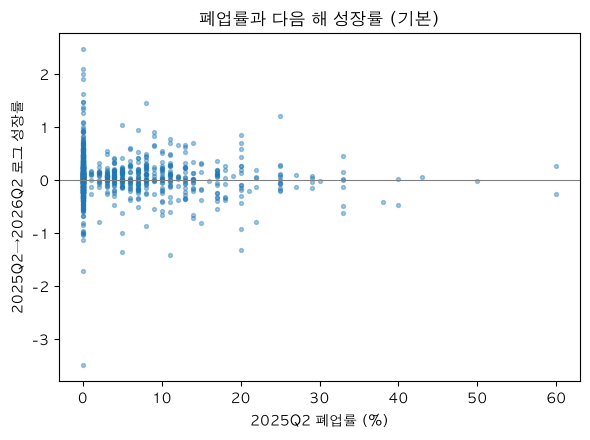

In [8]:
base6 = h6_versions['기본']

plt.figure(figsize=(6, 4.5))
plt.scatter(base6['폐업률_전'], base6['성장률_로그'], s=8, alpha=0.4)
plt.axhline(0, color='gray', linewidth=0.8)
plt.xlabel('2025Q2 폐업률 (%)')
plt.ylabel('2025Q2→2026Q2 로그 성장률')
plt.title('폐업률과 다음 해 성장률 (기본)')
plt.tight_layout()
plt.show()

#### 코드 읽기
- `plt.axhline(0, ...)`: y=0 위치에 가로선을 긋습니다. 선 위는 성장, 아래는 감소입니다.
- 폐업률이 0, 7, 10, 14처럼 띄엄띄엄 세로줄로 모여 보이면 점포 수가 적어서 폐업 한두 건에 비율이 크게 움직인다는 뜻입니다.

In [9]:
# 참고: 다른 해에도 같은 방향인지 (기본 버전만)
pairs = [(20212, 20222), (20222, 20232), (20232, 20242), (20242, 20252), (20252, 20262)]

result = []
for before_q, after_q in pairs:
    base_pair = make_versions(make_pair(before_q, after_q))['기본']
    r, p = stats.pearsonr(base_pair['폐업률_전'], base_pair['성장률_로그'])
    result.append({'기간': f'{before_q}→{after_q}', '상권_수': len(base_pair), 'r': round(r, 3), 'p값': p})

pd.DataFrame(result)

,기간,상권_수,r,p값
0,20212→20222,975,0.049,0.123410
1,20222→20232,990,0.063,0.046707
2,20232→20242,1002,0.034,0.287353
3,20242→20252,996,0.013,0.677283
4,20252→20262,982,-0.073,0.022153


#### 코드 읽기
- `pairs = [...]`: (앞 분기, 뒤 분기) 쌍을 해마다 2분기 기준으로 적었습니다.
- `for before_q, after_q in pairs:`: 쌍 하나를 꺼내 두 변수에 나눠 담습니다.
- `make_versions(make_pair(...))['기본']`: 두 분기를 붙이고, 세 버전 중 기본만 꺼냅니다. 함수 안에 함수를 넣어 한 줄로 썼습니다.
- `f'{before_q}→{after_q}'`: f-string입니다. 중괄호 안의 변수 값이 글자 안에 들어갑니다.
- 판정은 2단계에서 정한 2025Q2→2026Q2로만 하고 이 표는 참고용입니다.

다른 해에는 r이 0.013~0.063으로 오히려 양수입니다. 2022→2023은 양의 방향으로 p < 0.05까지 나옵니다. 폐업률과 다음 해 성장률의 관계는 해마다 방향이 바뀝니다. 위 산점도에서도 폐업률 0인 세로줄에 성장률이 위아래로 가장 넓게 퍼져 있습니다. 점포가 적은 상권은 폐업률도 성장률도 들쭉날쭉합니다.

H6은 "기준 충족, 결과 불안정"으로 판정합니다. 2단계 기준만 보면 지지지만 처리 방법을 바꾸거나 다른 해로 보면 유지되지 않습니다. 민감도 분석을 안 했다면 지지라고만 적고 넘어갔을 결과입니다. 폐업률을 후보를 거르는 기준으로 쓸지는 5단계에서 다시 정합니다.

## 정리

| 가설 | 판정 | 근거 | 처리 방법을 바꿨을 때 |
|---|---|---|---|
| H5 순위 유지 | 지지 | ρ = 0.907, 상위 10%의 74%가 2년 뒤에도 상위 10% | 세 버전 모두 0.9 이상 |
| H6 폐업률 | 기준 충족, 결과 불안정 | r = -0.073, p = 0.022 | 결제부족 포함 시 p = 0.109, 다른 해는 양수 |

5단계에서 후보를 고를 때 쓸 점
- 2026년 2분기 점포당 매출 순위를 후보 선정의 출발점으로 써도 됩니다.
- 상위권도 네 곳 중 한 곳은 밀려나니 최근 추세를 같이 봅니다.
- 폐업률은 점포가 적은 상권에서 들쭉날쭉해서 강한 기준으로 쓰기 어렵습니다.

## 확인 질문

<details>
<summary>1. H5에 스피어만을 쓰고 로그를 안 취한 이유는?</summary>

H5는 순위가 유지되는지를 묻는 가설이라 순위로 계산하는 스피어만이 맞습니다. 로그를 취해도 순위는 그대로라서 결과가 같습니다.
</details>

<details>
<summary>2. H6이 기준을 넘었는데 "결과 불안정"이라고 본 이유는?</summary>

결제부족을 포함하면 p = 0.109로 기준을 넘지 못하고, 다른 해에는 r이 오히려 양수였습니다. 처리 방법이나 연도를 조금만 바꿔도 결론이 달라집니다.
</details>

<details>
<summary>3. 폐업률이 들쭉날쭉한 이유는?</summary>

점포가 적은 상권은 분모가 작아서 한두 곳만 문을 닫아도 비율이 크게 움직입니다. 2025년 2분기에는 상권의 57%가 0%였습니다.
</details>

<details>
<summary>4. merge에서 suffixes=('_전', '_후')는 왜 필요한가요?</summary>

두 분기 표에 같은 이름의 컬럼(점포당_매출, 폐업률 등)이 있어서 붙이면 이름이 겹칩니다. 앞쪽에 _전, 뒤쪽에 _후를 붙여 구분합니다.
</details>

<details>
<summary>5. pandas 조건에 and 대신 &를 쓰고 괄호를 치는 이유는?</summary>

and는 값 하나끼리 비교할 때 쓰는 파이썬 문법이라 컬럼 전체(시리즈)에는 쓸 수 없습니다. &는 줄마다 따로 "그리고"를 계산합니다. &가 비교 연산자(==)보다 먼저 계산되기 때문에 조건마다 괄호를 쳐야 합니다.
</details>